# 1. Inspect one trajectory and compute both PT channels

This notebook uses **real supplied coordinates** but does not assign a bias or
claim an equilibrium FES. The included sample contains 121 of the supplied 2,401
frames (every twentieth retained frame), preserving original timestep comments.

The atom IDs you choose and the path-selection rule define the observable.
Inspect them before processing a full production trajectory. The underlying
ECToolkits path selector could not be retrieved here; exact legacy compatibility
is not asserted. See `docs/methods.md` and the legacy comparison tool.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from bivo4_fes import *

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
OUT = ROOT / "results"
OUT.mkdir(exist_ok=True)

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
TRAJECTORY = ROOT / "examples/data/sample.xyz.gz"
CELL = [10.39, 10.18, 36.17]  # confirm your actual cell; XYZ has no cell
MD_TIMESTEP_PS = None         # set to your ORIGINAL MD timestep for bias matching

symbols = xyz_symbols(TRAJECTORY)
first = next(iter_xyz(TRAJECTORY, cell=CELL))
print("Atoms:", len(symbols), "first stored MD step:", first.step)
print("Elements:", dict(zip(*np.unique(symbols, return_counts=True))))

Atoms: 360 first stored MD step: 0
Elements: {np.str_('Bi'): np.int64(24), np.str_('H'): np.int64(144), np.str_('O'): np.int64(168), np.str_('V'): np.int64(24)}


## Choose acceptors explicitly, or derive a frozen candidate group

Here the inputs are **one-based PLUMED IDs**. Low-level API arguments and all saved
results are zero-based. This demonstration list is not guaranteed to include every
relevant surface O in your run. The original colleague list included a
water-derived oxygen that became part of the solid; it is not silently assumed
here. `PTSelection.colleague(symbols)` is available to inspect that exact list.

`waters=None, slab_atoms=144` identifies water-derived oxygens by topology order.
You can instead provide `waters=[...]` manually. These sites may be H2O, OH, or
H3O at different times.

In [3]:
selection = PTSelection.from_symbols(
    symbols, donor=151, acceptors=[131, 137, 139, 140, 130],
    slab_atoms=144, index_base=1,
)
print("Donor Python / PLUMED:", selection.donor, selection.donor + 1)
print("Acceptors Python:", selection.acceptors)
print("Acceptors PLUMED:", selection.acceptors + 1)
print("Bridge candidates:", len(selection.waters), "hydrogens:", len(selection.hydrogens))

# Alternative selection building blocks; inspect the result before using it.
wrapped = first.positions % np.asarray(CELL)
bi_indices, water_o_indices = notebook_bi_water(symbols, wrapped)
print("First-frame surface Bi (PLUMED IDs):", bi_indices + 1)
print("Water O selected using the earlier z windows:", len(water_o_indices))

Donor Python / PLUMED: 150 151
Acceptors Python: [129 130 136 138 139]
Acceptors PLUMED: [130 131 137 139 140]
Bridge candidates: 71 hydrogens: 144
First-frame surface Bi (PLUMED IDs): [ 1  2  3  4 61 62 63 64]
Water O selected using the earlier z windows: 72


In [4]:
frames = iter_xyz(TRAJECTORY, cell=CELL, timestep_ps=MD_TIMESTEP_PS)
pt = analyze(frames, selection, cv_acceptor=130, keep_paths=True, progress=False)
pt.save(OUT / "sample_pt.npz")

print("Frames:", len(pt.frame))
print("Direct-connected:", pt.valid("direct").sum())
print("Indirect-connected:", pt.valid("indirect").sum())
print("Both:", np.sum(pt.valid("direct") & pt.valid("indirect")))
print("Neither:", np.sum(~pt.valid("direct") & ~pt.valid("indirect")))
print("Valid physical time available:", np.all(np.isfinite(pt.time)))

Frames: 121
Direct-connected: 51
Indirect-connected: 46
Both: 16
Neither: 40
Valid physical time available: False


## Inspect the new coordinates

These are geometric connections, not observed reaction events. A frame may belong
to both channels. Within each channel the default picks the shortest O-O route,
then the most linear angles; all candidates are also cached for sensitivity checks.

For direct PT, delta = r(Oad,H)-r(Oacceptor,H). For indirect PT, delta and dOO are
the averages of the two links; the individual link values remain accessible.

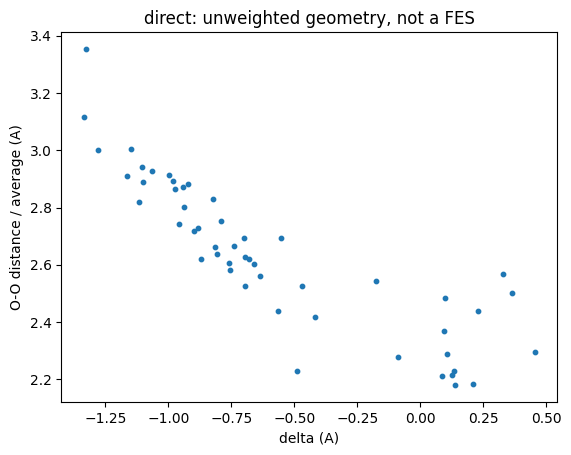

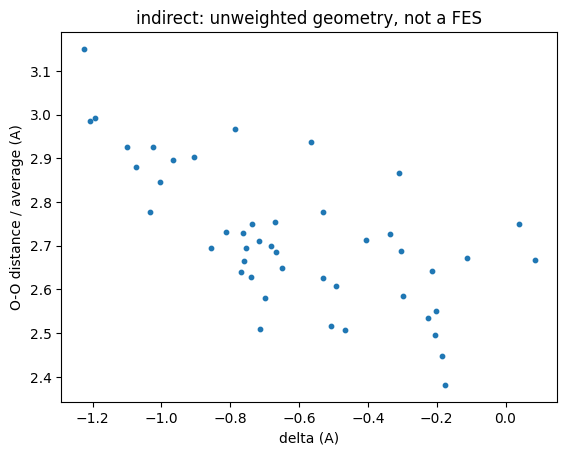

In [5]:
for channel in ("direct", "indirect"):
    q = pt.channel(channel)
    ok = pt.valid(channel)
    fig, ax = plt.subplots()
    ax.scatter(q["delta"][ok], q["distance"][ok], s=10)
    ax.set(xlabel="delta (A)", ylabel="O-O distance / average (A)",
           title=f"{channel}: unweighted geometry, not a FES")
    plt.show()

In [6]:
channel = "indirect"
q = pt.channel(channel)
ids = np.flatnonzero(pt.valid(channel))[:5]
for i in ids:
    print({"frame": int(pt.frame[i]), "step": int(pt.step[i]),
           "delta": float(q["delta"][i]), "d": float(q["distance"][i]),
           "acceptor_PLUMED": int(q["acceptor"][i]) + 1,
           "bridge_PLUMED": int(q["bridge"][i]) + 1,
           "H1_PLUMED": int(q["h1"][i]) + 1, "H2_PLUMED": int(q["h2"][i]) + 1})

print("All-path table shape:", pt.paths.shape)
# Columns: result-row, mechanism, delta, distance, acceptor, bridge, H1, H2,
#          delta1, delta2, d1, d2, angle_score.
# This table exposes ambiguous multi-path frames rather than hiding them.

{'frame': 5, 'step': 1000000, 'delta': -1.206185702365425, 'd': 2.9858757350932272, 'acceptor_PLUMED': 140, 'bridge_PLUMED': 237, 'H1_PLUMED': 249, 'H2_PLUMED': 280}
{'frame': 6, 'step': 1200000, 'delta': -0.7126265376136358, 'd': 2.50959499577875, 'acceptor_PLUMED': 140, 'bridge_PLUMED': 238, 'H1_PLUMED': 306, 'H2_PLUMED': 321}
{'frame': 7, 'step': 1400000, 'delta': -0.20272261593376295, 'd': 2.5503034628512875, 'acceptor_PLUMED': 139, 'bridge_PLUMED': 355, 'H1_PLUMED': 357, 'H2_PLUMED': 356}
{'frame': 10, 'step': 2000000, 'delta': -1.0238609746034917, 'd': 2.9251733708439502, 'acceptor_PLUMED': 139, 'bridge_PLUMED': 226, 'H1_PLUMED': 249, 'H2_PLUMED': 271}
{'frame': 12, 'step': 2400000, 'delta': -0.49249350428895833, 'd': 2.607697395458765, 'acceptor_PLUMED': 131, 'bridge_PLUMED': 182, 'H1_PLUMED': 196, 'H2_PLUMED': 195}
All-path table shape: (109, 13)


## Coordination and final-state labels

The donor and acceptor O-H coordination numbers are computed during the same pass
using r0=1.3 A, NN=12, MM=24. A label of -1 is deliberately unresolved: it can
mean no selected O is protonated, a shared proton, or multiple protonated sites.
It does **not** prove the proton is in solvent. Classify those cases separately.

The counts below are raw sampling counts, not unbiased populations. Reweighting
needs a matching COLVAR (not available for this sample).

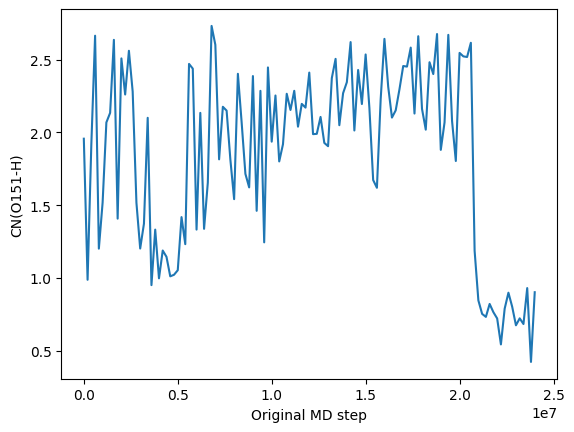

Raw product-frame site counts, Python indices (-1 unresolved):
{-1: 11, 130: 1, 138: 1, 139: 16}


In [7]:
fig, ax = plt.subplots()
ax.plot(pt.step, pt.donor_cn)
ax.set(xlabel="Original MD step", ylabel="CN(O151-H)")
plt.show()

site = protonated_site(pt.surface_cn, pt.acceptors)
product = pt.donor_cn < 1.3  # example basin definition; check your distribution
labels, counts = np.unique(site[product], return_counts=True)
print("Raw product-frame site counts, Python indices (-1 unresolved):")
print(dict(zip(labels.tolist(), counts.tolist())))

In [8]:
# Bi--water coordination uses the earlier notebook's smooth definition.
# This demonstration only computes the reference frame. All indices here are 0-based.
cn_bi = coordination(first.positions, bi_indices, water_o_indices, first.box,
                     r0=3.2, nn=6)
for bi, cn in zip(bi_indices, cn_bi):
    print(f"Bi {bi+1:3d} (PLUMED): water-derived O coordination {cn:.3f}")

Bi   1 (PLUMED): water-derived O coordination 1.859
Bi   2 (PLUMED): water-derived O coordination 1.583
Bi   3 (PLUMED): water-derived O coordination 1.681
Bi   4 (PLUMED): water-derived O coordination 2.530
Bi  61 (PLUMED): water-derived O coordination 2.234
Bi  62 (PLUMED): water-derived O coordination 2.587
Bi  63 (PLUMED): water-derived O coordination 1.922
Bi  64 (PLUMED): water-derived O coordination 2.447


## Scale to a production run

Use `analyze(iter_xyz(...), ...)` to retain only one coordinate frame at a time.
`keep_paths=False` reduces cache size when ambiguity diagnostics are unnecessary.
For bounded output batches use `analyze_chunks(..., chunk_size=5000)`, save each
chunk, and later join the observable caches using `PTResult.concatenate(...)`.

For LAMMPS, XTC, or DCD, construct an MDAnalysis Universe and pass
`iter_mdanalysis(u, timestep_ps=...)`. Confirm the topology order and original
clock, especially across restart segments. No automatic rescaling is guessed.